In [11]:
# ==========================================
# 0. IMPORT CÁC THƯ VIỆN CẦN THIẾT
# ==========================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torchsummary import summary
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

In [14]:
# ==========================================
# 1. TIỀN XỬ LÝ DỮ LIỆU
# ==========================================
# Tự động tìm tập tin .csv
input_file = ''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('.csv'):
            input_file = os.path.join(dirname, filename)
            break
    if input_file:
        break
df = pd.read_csv(input_file)

# --- Chuẩn hóa tên cột ---
# Xóa đơn vị và khoảng trắng thừa
df.columns = [
    c.split(' (')[0].strip().capitalize()
    for c in df.columns
]
print("Tên các cột sau khi chuẩn hóa:", df.columns.tolist())

# --- Mã hóa nhãn (Label) ---
le = LabelEncoder()
df['Label'] = le.fit_transform(df['Label'])

# --- Lấy dữ liệu đầu vào và nhãn ---
X = df[['Voltage', 'Current', 'Temperature', 'Vibration']].values
y = df['Label'].values

# ==========================================
# CHIA DỮ LIỆU: 70:10:20
# ==========================================

# Lần 1: Chia 80% Train + Validation và 20% Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Lần 2: Chia 80% còn lại thành:
# Training = 70/80 = 87.5%
# Validation = 10/80 = 12.5%
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.125,
    random_state=42,
    stratify=y_train_val
)

# ==========================================
# CHUẨN HÓA DỮ LIỆU
# ==========================================
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# ==========================================
# CHUYỂN SANG PYTORCH TENSOR
# ==========================================

X_train = torch.FloatTensor(X_train)
y_train = torch.LongTensor(y_train)

X_val = torch.FloatTensor(X_val)
y_val = torch.LongTensor(y_val)

X_test = torch.FloatTensor(X_test)
y_test = torch.LongTensor(y_test)

# ==========================================
# KIỂM TRA KÍCH THƯỚC CÁC TẬP DỮ LIỆU
# ==========================================

print("\nKích thước các tập dữ liệu:")
print("Training   :", X_train.size(), y_train.size())
print("Validation :", X_val.size(), y_val.size())
print("Testing    :", X_test.size(), y_test.size())

Tên các cột sau khi chuẩn hóa: ['Voltage', 'Current', 'Temperature', 'Vibration', 'Label']

Kích thước các tập dữ liệu:
Training   : torch.Size([5600, 4]) torch.Size([5600])
Validation : torch.Size([800, 4]) torch.Size([800])
Testing    : torch.Size([1600, 4]) torch.Size([1600])


In [15]:
# ==========================================
# 2. XÂY DỰNG MÔ HÌNH MẠNG NƠ-RON (ANN)
# ==========================================
class MotorRiskNet(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(MotorRiskNet, self).__init__()
        self.fc1 = nn.Linear(input_dim, 32) # Lớp ẩn 1
        self.fc2 = nn.Linear(32, 16)        # Lớp ẩn 2
        self.fc3 = nn.Linear(16, output_dim)#Lớp đầu ra (4 lớp rủi ro)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x) 
        return x

model = MotorRiskNet(input_dim=4, output_dim=4)

# Hiển thị tóm tắt cấu trúc mô hình
# (4,) là kích thước vector đầu vào: [Voltage, Current, Temperature, Vibration]
summary(model, input_size=(4,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                   [-1, 32]             160
              ReLU-2                   [-1, 32]               0
            Linear-3                   [-1, 16]             528
              ReLU-4                   [-1, 16]               0
            Linear-5                    [-1, 4]              68
Total params: 756
Trainable params: 756
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


In [5]:

# ==========================================
# 3. HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH
# ==========================================

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

epochs = 100

# Lưu lịch sử Loss và Accuracy
train_loss_history = []
val_loss_history = []

train_acc_history = []
val_acc_history = []

print("Bắt đầu quá trình huấn luyện...")

for epoch in range(epochs):

    # ======================================
    # A. TRAINING PHASE
    # ======================================
    model.train()

    # Forward pass
    outputs = model(X_train)
    loss = criterion(outputs, y_train)

    # Backward pass và cập nhật trọng số
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Tính Training Accuracy
    _, predicted = torch.max(outputs.data, 1)
    train_correct = (predicted == y_train).sum().item()
    train_acc = train_correct / y_train.size(0)

    # Lưu lịch sử Training
    train_loss_history.append(loss.item())
    train_acc_history.append(train_acc)

    # ======================================
    # B. VALIDATION PHASE
    # ======================================
    model.eval()

    with torch.no_grad():

        # Dự đoán trên tập Validation
        val_outputs = model(X_val)

        # Tính Validation Loss
        val_loss = criterion(val_outputs, y_val)

        # Tính Validation Accuracy
        _, val_predicted = torch.max(val_outputs.data, 1)
        val_correct = (val_predicted == y_val).sum().item()
        val_acc = val_correct / y_val.size(0)

    # Lưu lịch sử Validation
    val_loss_history.append(val_loss.item())
    val_acc_history.append(val_acc)

    # ======================================
    # C. HIỂN THỊ KẾT QUẢ
    # ======================================
    if (epoch + 1) % 10 == 0:
        print(
            f'Epoch [{epoch+1}/{epochs}] | '
            f'Train Loss: {loss.item():.4f} | '
            f'Val Loss: {val_loss.item():.4f} | '
            f'Train Acc: {train_acc*100:.2f}% | '
            f'Val Acc: {val_acc*100:.2f}%'
        )

print("\nHoàn thành quá trình huấn luyện!")


Bắt đầu quá trình huấn luyện...
Epoch [10/100] | Train Loss: 1.2616 | Val Loss: 1.2430 | Train Acc: 63.27% | Val Acc: 62.50%
Epoch [20/100] | Train Loss: 0.9638 | Val Loss: 0.9323 | Train Acc: 63.82% | Val Acc: 64.25%
Epoch [30/100] | Train Loss: 0.6603 | Val Loss: 0.6414 | Train Acc: 77.18% | Val Acc: 78.88%
Epoch [40/100] | Train Loss: 0.4837 | Val Loss: 0.4751 | Train Acc: 84.14% | Val Acc: 84.62%
Epoch [50/100] | Train Loss: 0.3802 | Val Loss: 0.3788 | Train Acc: 86.61% | Val Acc: 86.12%
Epoch [60/100] | Train Loss: 0.3150 | Val Loss: 0.3155 | Train Acc: 87.71% | Val Acc: 87.75%
Epoch [70/100] | Train Loss: 0.2696 | Val Loss: 0.2724 | Train Acc: 89.12% | Val Acc: 88.62%
Epoch [80/100] | Train Loss: 0.2368 | Val Loss: 0.2421 | Train Acc: 90.32% | Val Acc: 90.12%
Epoch [90/100] | Train Loss: 0.2154 | Val Loss: 0.2227 | Train Acc: 91.16% | Val Acc: 90.38%
Epoch [100/100] | Train Loss: 0.2022 | Val Loss: 0.2100 | Train Acc: 91.66% | Val Acc: 91.25%

Hoàn thành quá trình huấn luyện!


In [6]:
# ==========================================
# 4. ĐÁNH GIÁ KẾT QUẢ
# ==========================================
model.eval() # Chuyển mô hình sang chế độ đánh giá
with torch.no_grad():
    y_pred_logits = model(X_test)
    _, y_pred = torch.max(y_pred_logits, 1)

# In báo cáo chi tiết: Precision, Recall, F1-Score
print("\nBÁO CÁO HIỆU SUẤT MÔ HÌNH:")
print(classification_report(y_test, y_pred, target_names=le.classes_))



BÁO CÁO HIỆU SUẤT MÔ HÌNH:
              precision    recall  f1-score   support

        high       1.00      1.00      1.00       400
         low       0.85      0.81      0.83       400
    moderate       0.99      0.98      0.99       400
      normal       0.83      0.87      0.85       400

    accuracy                           0.92      1600
   macro avg       0.92      0.92      0.92      1600
weighted avg       0.92      0.92      0.92      1600



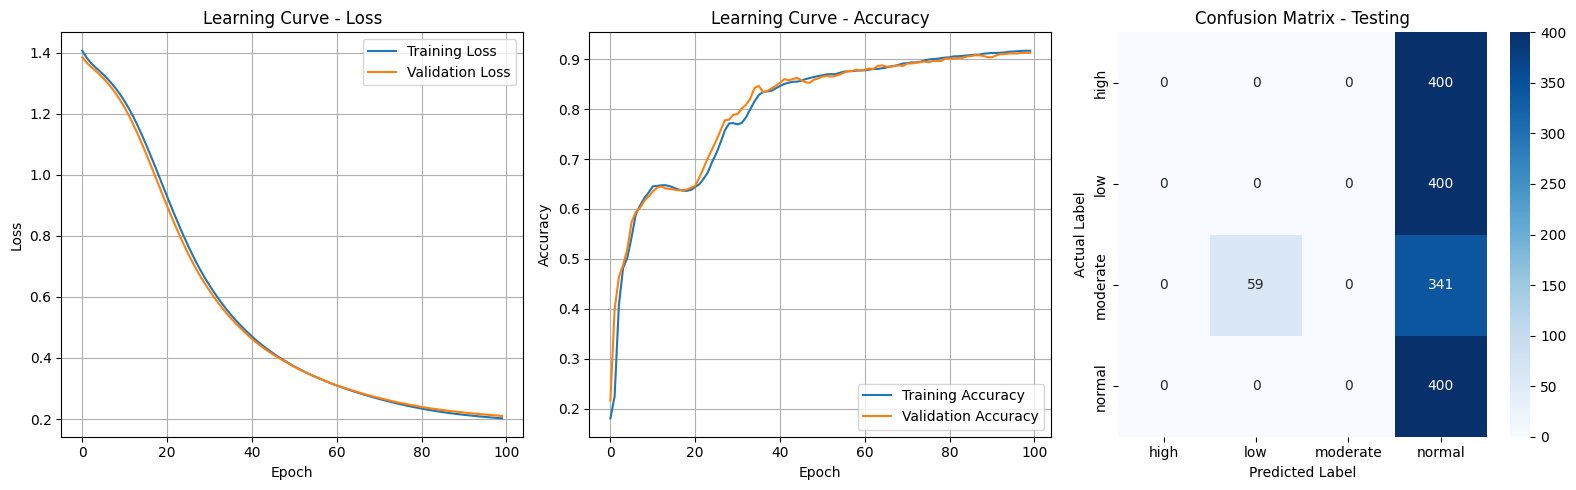


Classification Report:
              precision    recall  f1-score   support

        high       0.00      0.00      0.00       400
         low       0.00      0.00      0.00       400
    moderate       0.00      0.00      0.00       400
      normal       0.26      1.00      0.41       400

    accuracy                           0.25      1600
   macro avg       0.06      0.25      0.10      1600
weighted avg       0.06      0.25      0.10      1600


Đã lưu mô hình thành công: motor_risk_model.pth


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


<Figure size 640x480 with 0 Axes>

In [16]:
# ==========================================
# 5. TRỰC QUAN HÓA VÀ ĐÁNH GIÁ MÔ HÌNH
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# ==========================================
# A. DỰ ĐOÁN TRÊN TẬP TESTING
# ==========================================

model.eval()

with torch.no_grad():
    outputs = model(X_test)
    _, y_pred = torch.max(outputs, 1)

# Chuyển Tensor về NumPy để đánh giá
y_pred = y_pred.cpu().numpy()
y_true = y_test.cpu().numpy()

# ==========================================
# B. TRỰC QUAN HÓA LEARNING CURVE
# ==========================================

plt.figure(figsize=(16, 5))

# ------------------------------------------
# 1. Loss Curve
# ------------------------------------------
plt.subplot(1, 3, 1)

plt.plot(train_loss_history, label='Training Loss')
plt.plot(val_loss_history, label='Validation Loss')

plt.title('Learning Curve - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# ------------------------------------------
# 2. Accuracy Curve
# ------------------------------------------
plt.subplot(1, 3, 2)

plt.plot(train_acc_history, label='Training Accuracy')
plt.plot(val_acc_history, label='Validation Accuracy')

plt.title('Learning Curve - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# ------------------------------------------
# 3. Confusion Matrix
# ------------------------------------------
plt.subplot(1, 3, 3)

cm = confusion_matrix(y_true, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title('Confusion Matrix - Testing')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')

plt.tight_layout()
plt.show()


# ==========================================
# C. BÁO CÁO ĐÁNH GIÁ MÔ HÌNH
# ==========================================

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=[str(c) for c in le.classes_]
))

# ==========================================
# D. LƯU MÔ HÌNH
# ==========================================

torch.save(model.state_dict(), 'motor_risk_model.pth')

print("\nĐã lưu mô hình thành công: motor_risk_model.pth")


In [10]:

# ==========================================
# 6. TRIỂN KHAI MÔ HÌNH ANN
# ==========================================

# a. Tái thiết lập cấu trúc mạng
model_deploy = MotorRiskNet(input_dim=4, output_dim=4)

# b. Nạp trọng số đã lưu
model_deploy.load_state_dict(
    torch.load('motor_risk_model.pth', map_location='cpu')
)
model_deploy.eval()

# c. Giả lập dữ liệu mới từ cảm biến
# Voltage, Current, Temperature, Vibration
new_sensor_data = np.array([[215.0, 8.5, 85.0, 12.0]])

# d. Chuẩn hóa dữ liệu mới
new_sensor_data_scaled = scaler.transform(new_sensor_data)
input_tensor = torch.FloatTensor(new_sensor_data_scaled)

# e. Thực hiện dự báo
with torch.no_grad():
    prediction_logits = model_deploy(input_tensor)

    # Chuyển logits thành xác suất bằng Softmax
    probabilities = torch.softmax(prediction_logits, dim=1)

    # Lấy lớp có xác suất cao nhất
    confidence, predicted_class = torch.max(probabilities, dim=1)

# f. Giải mã kết quả
risk_level = le.inverse_transform(
    [predicted_class.item()]
)[0]

# ==========================================
# g. HIỂN THỊ KẾT QUẢ DỰ ĐOÁN
# ==========================================

print("\n====================================")
print("       KẾT QUẢ DỰ ĐOÁN ANN")
print("====================================")

print(f"Mức độ rủi ro dự đoán: {risk_level}")
print(f"Độ tin cậy dự đoán: {confidence.item()*100:.2f}%")

print("\nXác suất dự đoán của từng lớp:")

# Lấy xác suất của tất cả các lớp
probs = probabilities.squeeze().numpy()

for i, class_name in enumerate(le.classes_):
    print(f"{class_name}: {probs[i]*100:.2f}%")

print("====================================")



       KẾT QUẢ DỰ ĐOÁN ANN
Mức độ rủi ro dự đoán: moderate
Độ tin cậy dự đoán: 74.63%

Xác suất dự đoán của từng lớp:
high: 25.37%
low: 0.00%
moderate: 74.63%
normal: 0.00%
